In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv('/content/Bird_Migration_Data_with_Origin.csv')

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,Bird_ID,Species,Region,Habitat,Weather_Condition,Migration_Reason,Start_Latitude,Start_Longitude,End_Latitude,End_Longitude,...,Migration_Interrupted,Interrupted_Reason,Tagged_By,Tag_Weight_g,Migration_Success,Recovery_Location_Known,Recovery_Time_days,Observation_Counts,Observation_Quality,Origin
0,B1000,Warbler,South America,Grassland,Stormy,Feeding,11.906566,-169.378251,30.377647,-21.366879,...,Yes,Storm,Researcher_A,27.0,Failed,No,102,56,Low,"11.906566441337574, -169.37825068830264"
1,B1001,Stork,North America,Grassland,Stormy,Breeding,62.301546,-111.475069,39.921092,47.963436,...,Yes,Injury,Researcher_C,14.2,Successful,Yes,118,61,Low,"62.301545854189925, -111.47506945435978"
2,B1002,Hawk,South America,Mountain,Stormy,Avoid Predators,87.861164,-78.727327,66.990980,19.448466,...,No,Lost Signal,Researcher_B,16.1,Failed,No,41,71,High,"87.86116387126651, -78.72732718179907"
3,B1003,Warbler,South America,Urban,Stormy,Climate Change,35.770590,153.104341,-49.003145,-157.868744,...,Yes,Lost Signal,Researcher_C,24.4,Successful,No,15,68,Low,"35.77058955392532, 153.1043405316318"
4,B1004,Crane,Europe,Urban,Windy,Avoid Predators,-21.611614,106.674824,11.681051,-115.022863,...,No,NaN,Researcher_B,25.8,Failed,Yes,73,67,Moderate,"-21.611614380025586, 106.67482429343966"


In [6]:
df.tail()

,Bird_ID,Species,Region,Habitat,Weather_Condition,Migration_Reason,Start_Latitude,Start_Longitude,End_Latitude,End_Longitude,...,Migration_Interrupted,Interrupted_Reason,Tagged_By,Tag_Weight_g,Migration_Success,Recovery_Location_Known,Recovery_Time_days,Observation_Counts,Observation_Quality,Origin
9995,B10995,Crane,Africa,Wetland,Windy,Climate Change,-80.397410,87.638661,74.628139,-1.283046,...,Yes,Predator,Researcher_C,20.6,Successful,No,99,59,Low,"-80.39740960510355, 87.6386606594711"
9996,B10996,Hawk,Europe,Forest,Windy,Avoid Predators,-47.192670,2.850794,20.149497,-77.025629,...,Yes,Predator,Researcher_B,7.8,Failed,No,117,82,Moderate,"-47.19267029278711, 2.8507940097474886"
9997,B10997,Goose,Europe,Wetland,Stormy,Avoid Predators,32.392299,-32.037925,28.625721,-13.844319,...,No,Lost Signal,Researcher_B,17.8,Failed,No,79,66,High,"32.39229860010022, -32.037925286267495"
9998,B10998,Crane,South America,Mountain,Stormy,Breeding,-41.145112,84.837740,74.612320,-74.675591,...,Yes,Lost Signal,Researcher_C,5.5,Successful,No,29,18,High,"-41.14511237593718, 84.83774044917067"
9999,B10999,Goose,Asia,Mountain,Stormy,Avoid Predators,56.593853,67.364781,4.812286,71.982278,...,No,Lost Signal,Researcher_C,21.4,Failed,Yes,71,59,Low,"56.59385290872976, 67.36478059664458"


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 42 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Bird_ID                  10000 non-null  object 
 1   Species                  10000 non-null  object 
 2   Region                   10000 non-null  object 
 3   Habitat                  10000 non-null  object 
 4   Weather_Condition        10000 non-null  object 
 5   Migration_Reason         10000 non-null  object 
 6   Start_Latitude           10000 non-null  float64
 7   Start_Longitude          10000 non-null  float64
 8   End_Latitude             10000 non-null  float64
 9   End_Longitude            10000 non-null  float64
 10  Flight_Distance_km       10000 non-null  float64
 11  Flight_Duration_hours    10000 non-null  float64
 12  Average_Speed_kmph       10000 non-null  float64
 13  Max_Altitude_m           10000 non-null  int64  
 14  Min_Altitude_m         

In [9]:
df.describe()

,Start_Latitude,Start_Longitude,End_Latitude,End_Longitude,Flight_Distance_km,Flight_Duration_hours,Average_Speed_kmph,Max_Altitude_m,Min_Altitude_m,Temperature_C,...,Pressure_hPa,Visibility_km,Tag_Battery_Level_%,Signal_Strength_dB,Rest_Stops,Predator_Sightings,Flock_Size,Tag_Weight_g,Recovery_Time_days,Observation_Counts
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.0000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,-0.321812,-0.394588,0.084391,0.467617,2504.036134,49.994020,49.953394,5504.80830,500.111800,12.566930,...,1000.440810,10.636970,54.651800,-69.8408,7.380000,4.490200,248.714500,17.605870,60.490800,49.872800
std,51.919190,104.083440,51.709437,103.438134,499.723298,10.026108,5.085296,2595.28577,229.782907,13.073405,...,28.959614,5.504623,25.839271,9.9189,4.023583,2.872826,144.943771,7.200088,34.434028,28.601997
min,-89.999003,-179.993975,-89.998482,-179.902756,527.700000,12.600000,30.430000,1000.00000,100.000000,-10.000000,...,950.000000,1.000000,10.000000,-107.9000,1.000000,0.000000,1.000000,5.000000,1.000000,1.000000
25%,-45.390697,-91.444680,-43.664719,-88.871564,2169.632500,43.200000,46.530000,3277.75000,300.000000,1.200000,...,975.000000,5.900000,32.000000,-76.6000,4.000000,2.000000,124.000000,11.400000,31.000000,25.000000
50%,-0.138849,-0.479892,-0.163116,1.280823,2511.150000,50.050000,50.040000,5521.00000,501.000000,12.500000,...,1000.950000,10.700000,55.000000,-69.8000,7.000000,5.000000,248.000000,17.700000,61.000000,50.000000
75%,44.480926,89.640253,44.957102,91.196076,2841.452500,56.800000,53.360000,7740.25000,698.000000,24.000000,...,1025.500000,15.400000,77.000000,-63.1000,11.000000,7.000000,376.000000,24.000000,91.000000,74.000000
max,89.980302,179.989973,89.989145,179.955036,4428.320000,91.000000,68.950000,9999.00000,899.000000,35.000000,...,1050.000000,20.000000,99.000000,-33.3000,14.000000,9.000000,499.000000,30.000000,119.000000,99.000000


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 42


In [11]:
print(df.isnull().sum())

Bird_ID                       0
Species                       0
Region                        0
Habitat                       0
Weather_Condition             0
Migration_Reason              0
Start_Latitude                0
Start_Longitude               0
End_Latitude                  0
End_Longitude                 0
Flight_Distance_km            0
Flight_Duration_hours         0
Average_Speed_kmph            0
Max_Altitude_m                0
Min_Altitude_m                0
Temperature_C                 0
Wind_Speed_kmph               0
Humidity_%                    0
Pressure_hPa                  0
Visibility_km                 0
Nesting_Success               0
Tag_Battery_Level_%           0
Signal_Strength_dB            0
Migration_Start_Month         0
Migration_End_Month           0
Rest_Stops                    0
Predator_Sightings            0
Tag_Type                      0
Migrated_in_Flock             0
Flock_Size                    0
Food_Supply_Level             0
Tracking

In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
print(df['Migration_Success'].value_counts())

Migration_Success
Successful    5094
Failed        4906
Name: count, dtype: int64


In [14]:
# Create a copy of the original dataset
df_clean = df.copy()

print("Original dataset:", df.shape)
print("Clean dataset:", df_clean.shape)

Original dataset: (10000, 42)
Clean dataset: (10000, 42)


In [15]:
# Replace missing values in Interrupted_Reason
df_clean['Interrupted_Reason'] = (
    df_clean['Interrupted_Reason'].fillna('Unknown')
)

print("Missing values handled successfully!")

Missing values handled successfully!


In [16]:
print("Missing values after preprocessing:")

print(df_clean.isnull().sum().sum())

Missing values after preprocessing:
0


In [17]:
# Count duplicate rows
print("Number of duplicate rows:", df_clean.duplicated().sum())

Number of duplicate rows: 0


In [18]:
# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

print("Dataset shape after removing duplicates:", df_clean.shape)

Dataset shape after removing duplicates: (10000, 42)


In [19]:
# Numerical columns
numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

# Categorical columns
categorical_columns = df_clean.select_dtypes(
    include=['object']
).columns

print("Numerical columns:")
print(list(numerical_columns))

print("\nCategorical columns:")
print(list(categorical_columns))

Numerical columns:
['Start_Latitude', 'Start_Longitude', 'End_Latitude', 'End_Longitude', 'Flight_Distance_km', 'Flight_Duration_hours', 'Average_Speed_kmph', 'Max_Altitude_m', 'Min_Altitude_m', 'Temperature_C', 'Wind_Speed_kmph', 'Humidity_%', 'Pressure_hPa', 'Visibility_km', 'Tag_Battery_Level_%', 'Signal_Strength_dB', 'Rest_Stops', 'Predator_Sightings', 'Flock_Size', 'Tag_Weight_g', 'Recovery_Time_days', 'Observation_Counts']

Categorical columns:
['Bird_ID', 'Species', 'Region', 'Habitat', 'Weather_Condition', 'Migration_Reason', 'Nesting_Success', 'Migration_Start_Month', 'Migration_End_Month', 'Tag_Type', 'Migrated_in_Flock', 'Food_Supply_Level', 'Tracking_Quality', 'Migration_Interrupted', 'Interrupted_Reason', 'Tagged_By', 'Migration_Success', 'Recovery_Location_Known', 'Observation_Quality', 'Origin']


In [20]:
print("Final dataset information:")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

print("\nTotal missing values:",
      df_clean.isnull().sum().sum())

print("\nTotal duplicate rows:",
      df_clean.duplicated().sum())

Final dataset information:
Rows: 10000
Columns: 42

Total missing values: 0

Total duplicate rows: 0


In [21]:
# Select useful input features
feature_columns = [
    'Species',
    'Region',
    'Habitat',
    'Weather_Condition',
    'Migration_Reason',
    'Start_Latitude',
    'Start_Longitude',
    'Temperature_C',
    'Wind_Speed_kmph',
    'Humidity_%',
    'Pressure_hPa',
    'Visibility_km',
    'Nesting_Success',
    'Tag_Battery_Level_%',
    'Signal_Strength_dB',
    'Migration_Start_Month',
    'Tag_Type',
    'Migrated_in_Flock',
    'Flock_Size',
    'Food_Supply_Level',
    'Tagged_By',
    'Tag_Weight_g',
    'Origin'
]

# Independent variables
X = df_clean[feature_columns].copy()

# Dependent variable
y = df_clean['Migration_Success'].copy()

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (10000, 23)
Target (y) shape: (10000,)


In [22]:
# Find numerical columns in X
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Find categorical columns in X
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numeric_features)

print("\nCategorical columns:")
print(categorical_features)

Numerical features: 11
Categorical features: 12

Numerical columns:
['Start_Latitude', 'Start_Longitude', 'Temperature_C', 'Wind_Speed_kmph', 'Humidity_%', 'Pressure_hPa', 'Visibility_km', 'Tag_Battery_Level_%', 'Signal_Strength_dB', 'Flock_Size', 'Tag_Weight_g']

Categorical columns:
['Species', 'Region', 'Habitat', 'Weather_Condition', 'Migration_Reason', 'Nesting_Success', 'Migration_Start_Month', 'Tag_Type', 'Migrated_in_Flock', 'Food_Supply_Level', 'Tagged_By', 'Origin']


In [23]:
print("Target classes:")
print(y.value_counts())

print("\nUnique target values:")
print(y.unique())

Target classes:
Migration_Success
Successful    5094
Failed        4906
Name: count, dtype: int64

Unique target values:
['Failed' 'Successful']


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical',
         OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)

print("One-Hot Encoding transformer created successfully!")

One-Hot Encoding transformer created successfully!


In [26]:
print("Preprocessing configuration:")
print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Total input features:", X.shape[1])

print("\nTarget variable:", y.name)
print("Target classes:", y.nunique())

Preprocessing configuration:
Numerical columns: 11
Categorical columns: 12
Total input features: 23

Target variable: Migration_Success
Target classes: 2


In [27]:
X = df_clean[feature_columns].copy()

y = df_clean['Migration_Success'].copy()

In [28]:
from sklearn.model_selection import train_test_split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (8000, 23)
Testing data: (2000, 23)
Training target: (8000,)
Testing target: (2000,)


In [32]:
print("Training class distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting class distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training class distribution:
Migration_Success
Successful    50.9375
Failed        49.0625
Name: proportion, dtype: float64

Testing class distribution:
Migration_Success
Successful    50.95
Failed        49.05
Name: proportion, dtype: float64


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [34]:
# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [35]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    n_jobs=-1
)

print("Random Forest model created successfully!")

Random Forest model created successfully!


In [36]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', rf_model)
])

print("Complete Random Forest pipeline created!")

Complete Random Forest pipeline created!


In [37]:
# Train Random Forest using training data
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [38]:
# Make predictions
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

Predictions generated successfully!

First 10 predictions:
['Successful' 'Successful' 'Failed' 'Failed' 'Failed' 'Failed' 'Failed'
 'Successful' 'Successful' 'Successful']


In [39]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))

       Actual   Predicted
0  Successful  Successful
1  Successful  Successful
2      Failed      Failed
3  Successful      Failed
4      Failed      Failed
5      Failed      Failed
6      Failed      Failed
7  Successful  Successful
8      Failed  Successful
9  Successful  Successful


In [40]:

# Train the Random Forest model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [41]:

# Predict migration success for test data
y_pred = model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])


Predictions generated successfully!

First 10 predictions:
['Successful' 'Successful' 'Failed' 'Failed' 'Failed' 'Failed' 'Failed'
 'Successful' 'Successful' 'Successful']


In [42]:

comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print(comparison.head(10))


       Actual   Predicted
0  Successful  Successful
1  Successful  Successful
2      Failed      Failed
3  Successful      Failed
4      Failed      Failed
5      Failed      Failed
6      Failed      Failed
7  Successful  Successful
8      Failed  Successful
9  Successful  Successful


In [43]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, pos_label='Successful'
)

recall = recall_score(
    y_test, y_pred, pos_label='Successful'
)

f1 = f1_score(
    y_test, y_pred, pos_label='Successful'
)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")


MODEL EVALUATION RESULTS
------------------------
Accuracy : 50.45 %
Precision: 51.28 %
Recall   : 55.25 %
F1 Score : 53.19 %


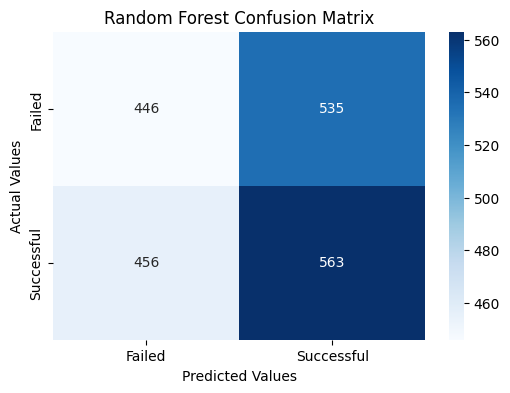

In [44]:

import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Failed', 'Successful']
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Failed', 'Successful'],
    yticklabels=['Failed', 'Successful']
)

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("Random Forest Confusion Matrix")

plt.show()


In [45]:

print(classification_report(
    y_test,
    y_pred,
    labels=['Failed', 'Successful'],
    zero_division=0
))


              precision    recall  f1-score   support

      Failed       0.49      0.45      0.47       981
  Successful       0.51      0.55      0.53      1019

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000



In [46]:

# Get the trained Random Forest classifier
rf = model.named_steps['classifier']

# Get feature names after preprocessing
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

# Get feature importance values
importances = rf.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print("Top 15 Important Features:")
print(importance_df.head(15))


Top 15 Important Features:
                          Feature  Importance
3            num__Wind_Speed_kmph    0.039049
2              num__Temperature_C    0.038669
8         num__Signal_Strength_dB    0.038366
1            num__Start_Longitude    0.038275
10              num__Tag_Weight_g    0.038161
0             num__Start_Latitude    0.037738
6              num__Visibility_km    0.037657
9                 num__Flock_Size    0.037657
5               num__Pressure_hPa    0.037567
7        num__Tag_Battery_Level_%    0.036942
4                 num__Humidity_%    0.036581
40       cat__Nesting_Success_Yes    0.009237
56  cat__Food_Supply_Level_Medium    0.009210
39        cat__Nesting_Success_No    0.009198
52      cat__Migrated_in_Flock_No    0.009197


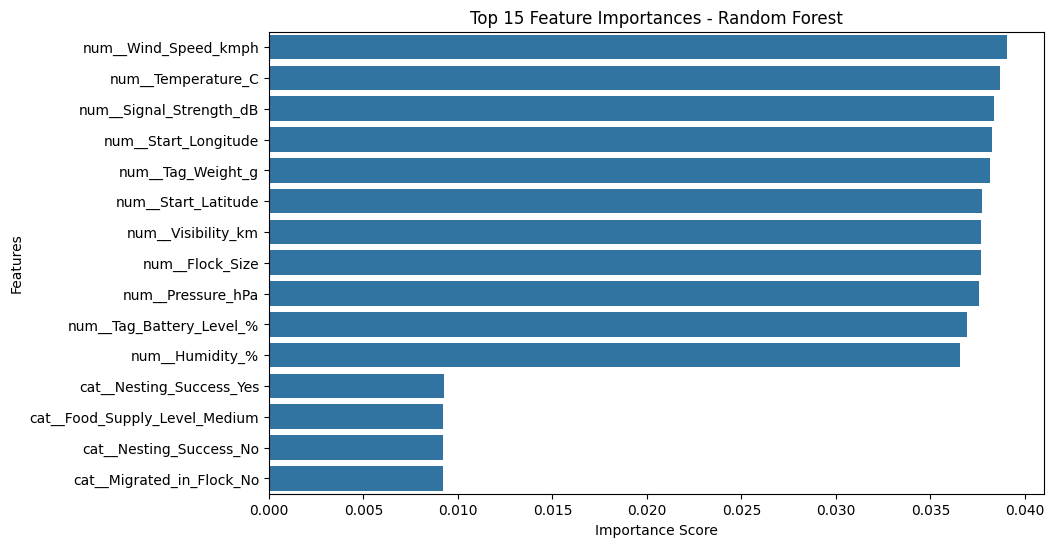

In [47]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()


In [48]:
required_variables = [
    'model', 'X_test', 'y_test',
    'numeric_features', 'categorical_features',
    'df_clean'
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise ValueError(
        "Missing variables: " + ", ".join(missing_variables) +
        ". Please run your previous project cells first."
    )

print("All required project variables are available.")


All required project variables are available.


In [49]:
y_pred = model.predict(X_test)

print("\nPredictions generated successfully.")




Predictions generated successfully.


In [50]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

cm = confusion_matrix(
    y_test, y_pred,
    labels=['Failed', 'Successful']
)

print("\n========== FINAL MODEL PERFORMANCE ==========")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test, y_pred,
    labels=['Failed', 'Successful'],
    zero_division=0
))



========== FINAL MODEL PERFORMANCE ==========
Accuracy  : 50.45%
Precision : 51.28%
Recall    : 55.25%
F1 Score  : 53.19%

Detailed Classification Report:
              precision    recall  f1-score   support

      Failed       0.49      0.45      0.47       981
  Successful       0.51      0.55      0.53      1019

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000



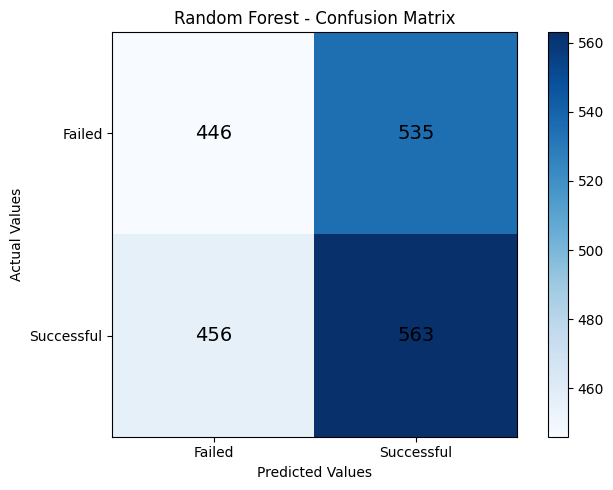

In [51]:
plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title("Random Forest - Confusion Matrix")
plt.colorbar()

classes = ['Failed', 'Successful']
plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha='center', va='center',
            fontsize=14
        )

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [52]:
rf = model.named_steps['classifier']

feature_names = (
    model.named_steps['preprocessor']
    .get_feature_names_out()
)

importances = rf.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
)

print("\n========== TOP 15 ENCODED FEATURES ==========")
display(importance_df.head(15))



========== TOP 15 ENCODED FEATURES ==========


,Feature,Importance
3,num__Wind_Speed_kmph,0.039049
2,num__Temperature_C,0.038669
8,num__Signal_Strength_dB,0.038366
1,num__Start_Longitude,0.038275
10,num__Tag_Weight_g,0.038161
0,num__Start_Latitude,0.037738
6,num__Visibility_km,0.037657
9,num__Flock_Size,0.037657
5,num__Pressure_hPa,0.037567
7,num__Tag_Battery_Level_%,0.036942


In [53]:
original_importance = {}

for col in numeric_features:
    prefix = f'num__{col}'
    mask = feature_names == prefix
    original_importance[col] = importances[mask].sum()

for col in categorical_features:
    prefix = f'cat__{col}_'
    mask = np.array([
        name.startswith(prefix) for name in feature_names
    ])
    original_importance[col] = importances[mask].sum()

original_importance_df = pd.DataFrame(
    list(original_importance.items()),
    columns=['Feature', 'Importance']
).sort_values(
    by='Importance',
    ascending=False
)

print("\n========== IMPORTANCE BY ORIGINAL FEATURE ==========")
display(original_importance_df)



========== IMPORTANCE BY ORIGINAL FEATURE ==========


,Feature,Importance
22,Origin,0.211520
17,Migration_Start_Month,0.052112
11,Species,0.047360
13,Habitat,0.043473
12,Region,0.043071
14,Weather_Condition,0.039588
3,Wind_Speed_kmph,0.039049
2,Temperature_C,0.038669
8,Signal_Strength_dB,0.038366
1,Start_Longitude,0.038275


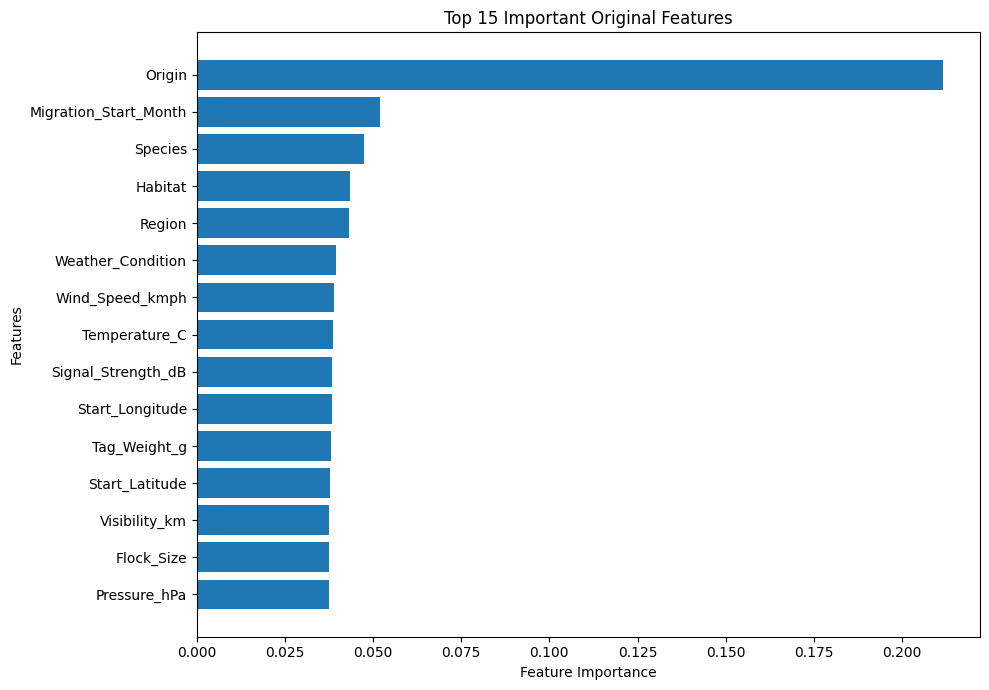

In [54]:
top_features = original_importance_df.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title("Top 15 Important Original Features")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig("feature_importance.png", dpi=150)
plt.show()


In [59]:

# STEP 8: SAVE MODEL AND FEATURE IMPORTANCE

# Import joblib
import joblib

# Save trained Random Forest model
joblib.dump(model, "/content/bird_migration_random_forest.joblib")

# Save feature importance CSV
original_importance_df.to_csv(
    "/content/bird_migration_feature_importance.csv",
    index=False
)

# Verify saved files
import os

print("Model file exists:",
      os.path.exists("/content/bird_migration_random_forest.joblib"))

print("Feature importance file exists:",
      os.path.exists("/content/bird_migration_feature_importance.csv"))

print("\nSTEP 8 COMPLETED SUCCESSFULLY!")


Model file exists: True
Feature importance file exists: True

STEP 8 COMPLETED SUCCESSFULLY!


In [60]:
dataset_name = "Bird_Migration_Data_with_Origin.csv"

total_rows = len(df_clean)
total_columns = len(df_clean.columns)

target_counts = df_clean['Migration_Success'].value_counts()

top_three = original_importance_df.head(3)

top_feature_text = ", ".join(
    top_three['Feature'].astype(str).tolist()
)

# Enter the verified Kaggle dataset URL here before submission.
# Do not invent or guess this URL.
KAGGLE_URL = ""

if KAGGLE_URL.strip():
    source_text = KAGGLE_URL.strip()
else:
    source_text = (
        "Not provided - verified Kaggle URL must be added "
        "before submission."
    )

if accuracy >= 0.70:
    conclusion = (
        "The model demonstrates reasonable predictive performance "
        "on the test data. Further validation is recommended."
    )
elif accuracy >= 0.55:
    conclusion = (
        "The model demonstrates limited predictive performance. "
        "Feature selection and hyperparameter tuning may be explored."
    )
else:
    conclusion = (
        "The model demonstrates weak predictive performance. "
        "The current features may not contain enough predictive "
        "information. Further data validation and feature analysis "
        "are necessary."
    )

All required variables found!

========== MODEL EVALUATION ==========
Accuracy  : 50.45%
Precision : 51.28%
Recall    : 55.25%
F1 Score  : 53.19%

Classification Report:
              precision    recall  f1-score   support

      Failed       0.49      0.45      0.47       981
  Successful       0.51      0.55      0.53      1019

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000



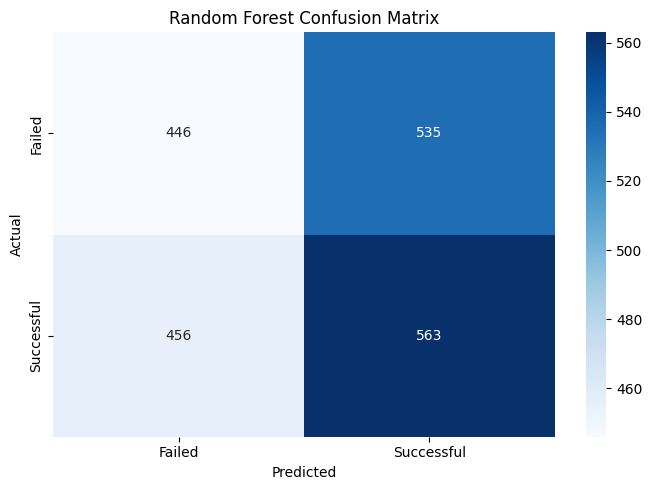


========== TOP 15 ENCODED FEATURES ==========


,Feature,Importance
3,num__Wind_Speed_kmph,0.039049
2,num__Temperature_C,0.038669
8,num__Signal_Strength_dB,0.038366
1,num__Start_Longitude,0.038275
10,num__Tag_Weight_g,0.038161
0,num__Start_Latitude,0.037738
6,num__Visibility_km,0.037657
9,num__Flock_Size,0.037657
5,num__Pressure_hPa,0.037567
7,num__Tag_Battery_Level_%,0.036942



========== ORIGINAL FEATURE IMPORTANCE ==========


,Feature,Importance
22,Origin,0.211520
17,Migration_Start_Month,0.052112
11,Species,0.047360
13,Habitat,0.043473
12,Region,0.043071
14,Weather_Condition,0.039588
3,Wind_Speed_kmph,0.039049
2,Temperature_C,0.038669
8,Signal_Strength_dB,0.038366
1,Start_Longitude,0.038275


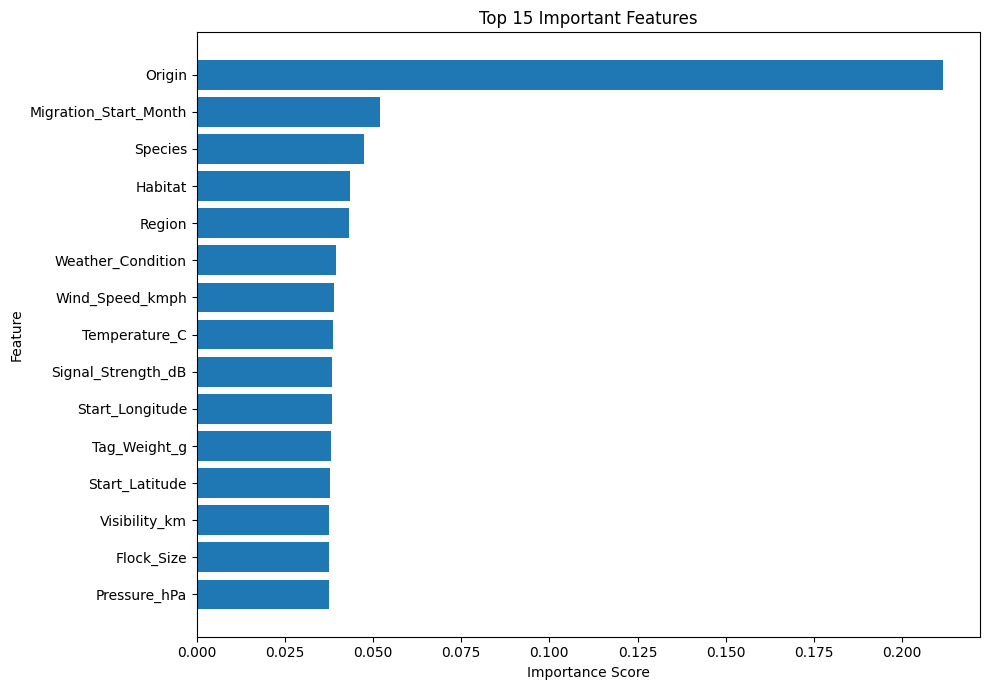


Model and feature importance saved!

PDF report created successfully!

========== FINAL PROJECT FILES ==========
SUCCESS: Bird_Migration_Project_Report.pdf


/content/Bird_Migration_Project_Report.pdf

SUCCESS: bird_migration_random_forest.joblib


/content/bird_migration_random_forest.joblib

SUCCESS: bird_migration_feature_importance.csv


/content/bird_migration_feature_importance.csv

SUCCESS: confusion_matrix.png


/content/confusion_matrix.png

SUCCESS: feature_importance.png


/content/feature_importance.png


FINAL PROJECT PROCESS COMPLETED!


In [62]:

# ==========================================================
# FINAL PROJECT: BIRD MIGRATION USING RANDOM FOREST
# COMPLETE CORRECTED VERSION
# ==========================================================

# STEP 1: IMPORT ALL REQUIRED LIBRARIES

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display, FileLink


# STEP 2: CHECK REQUIRED VARIABLES

required = [
    'model', 'X_test', 'y_test',
    'numeric_features', 'categorical_features',
    'df_clean'
]

missing = [v for v in required if v not in globals()]

if missing:
    raise ValueError(
        f"Missing variables: {missing}. "
        "Run your previous model-training cells first."
    )

print("All required variables found!")


# STEP 3: GENERATE PREDICTIONS

y_pred = model.predict(X_test)


# STEP 4: EVALUATE MODEL

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    pos_label='Successful',
    zero_division=0
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['Failed', 'Successful']
)

print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1 Score  : {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=['Failed', 'Successful'],
    zero_division=0
))


# STEP 5: CONFUSION MATRIX GRAPH

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Failed', 'Successful'],
    yticklabels=['Failed', 'Successful']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig("/content/confusion_matrix.png", dpi=150)
plt.show()
plt.close()


# STEP 6: FEATURE IMPORTANCE

rf = model.named_steps['classifier']

feature_names = (
    model.named_steps['preprocessor']
    .get_feature_names_out()
)

importances = rf.feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
)

print("\n========== TOP 15 ENCODED FEATURES ==========")
display(importance_df.head(15))


# STEP 7: COMBINE IMPORTANCE BY ORIGINAL FEATURE

original_importance = {}

for col in numeric_features:
    mask = feature_names == f'num__{col}'
    original_importance[col] = importances[mask].sum()

for col in categorical_features:
    prefix = f'cat__{col}_'
    mask = np.array([
        name.startswith(prefix) for name in feature_names
    ])
    original_importance[col] = importances[mask].sum()

original_importance_df = pd.DataFrame(
    list(original_importance.items()),
    columns=['Feature', 'Importance']
).sort_values(
    by='Importance',
    ascending=False
)

print("\n========== ORIGINAL FEATURE IMPORTANCE ==========")
display(original_importance_df)


# STEP 8: FEATURE IMPORTANCE GRAPH

top_features = (
    original_importance_df.head(15)
    .sort_values('Importance', ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig("/content/feature_importance.png", dpi=150)
plt.show()
plt.close()


# STEP 9: SAVE MODEL AND CSV

joblib.dump(
    model,
    "/content/bird_migration_random_forest.joblib"
)

original_importance_df.to_csv(
    "/content/bird_migration_feature_importance.csv",
    index=False
)

print("\nModel and feature importance saved!")


# STEP 10: PREPARE REPORT INFORMATION

dataset_name = "Bird_Migration_Data_with_Origin.csv"

total_rows = len(df_clean)
total_columns = len(df_clean.columns)

target_counts = df_clean['Migration_Success'].value_counts()

top_three = original_importance_df.head(3)

top_feature_text = ", ".join(
    top_three['Feature'].astype(str)
)

# Add the real Kaggle URL here after verifying its source.
KAGGLE_URL = ""

source_text = (
    KAGGLE_URL if KAGGLE_URL.strip()
    else "Kaggle source URL not verified - add before submission."
)

if accuracy >= 0.70:
    conclusion = (
        "The model shows reasonable predictive performance. "
        "Further validation is recommended."
    )
elif accuracy >= 0.55:
    conclusion = (
        "The model shows limited predictive performance. "
        "Further feature selection and tuning are recommended."
    )
else:
    conclusion = (
        "The model shows weak predictive performance. "
        "Further investigation of the dataset, feature quality "
        "and prediction timing is necessary."
    )


# STEP 11: CREATE ONE-PAGE PDF REPORT

report_text = f"""
RANDOM FOREST MACHINE LEARNING PROJECT

BIRD MIGRATION SUCCESS PREDICTION

1. OBJECTIVE
Predict whether bird migration is Successful or Failed
using a Random Forest classification algorithm.

2. DATASET
Name: {dataset_name}
Records: {total_rows}
Columns: {total_columns}
Target: Migration_Success

Target Distribution:
{target_counts.to_string()}

Kaggle Source:
{source_text}

3. DATA PREPROCESSING
- Explored the dataset and checked data types.
- Checked missing values and duplicate records.
- Replaced missing Interrupted_Reason with Unknown.
- Selected input features and target variable.
- Applied One-Hot Encoding to categorical features.
- Used a preprocessing pipeline.
- Split data into 80% training and 20% testing.

4. MODEL
Algorithm: Random Forest Classifier
Number of Trees: 100
Random State: 42

5. EVALUATION RESULTS
Accuracy: {accuracy * 100:.2f}%
Precision: {precision * 100:.2f}%
Recall: {recall * 100:.2f}%
F1 Score: {f1 * 100:.2f}%

Confusion Matrix:
                Predicted
              Failed  Successful
Actual Failed    {cm[0,0]}       {cm[0,1]}
Actual Successful {cm[1,0]}       {cm[1,1]}

6. FEATURE IMPORTANCE
Top three features:
{top_feature_text}

Feature importance shows how the model uses features.
It does not prove cause and effect.

7. CONCLUSION
{conclusion}

The current model should not be used for real-world
migration decisions without further validation.
"""

fig = plt.figure(figsize=(8.27, 11.69))

fig.text(
    0.07,
    0.96,
    report_text,
    va='top',
    ha='left',
    fontsize=8,
    family='monospace',
    linespacing=1.35
)

plt.axis('off')

pdf_path = "/content/Bird_Migration_Project_Report.pdf"

with PdfPages(pdf_path) as pdf:
    pdf.savefig(fig)

plt.close(fig)

print("\nPDF report created successfully!")


# STEP 12: VERIFY ALL GENERATED FILES

files = [
    "/content/Bird_Migration_Project_Report.pdf",
    "/content/bird_migration_random_forest.joblib",
    "/content/bird_migration_feature_importance.csv",
    "/content/confusion_matrix.png",
    "/content/feature_importance.png"
]

print("\n========== FINAL PROJECT FILES ==========")

for path in files:
    if os.path.exists(path):
        print("SUCCESS:", os.path.basename(path))
        display(FileLink(path))
    else:
        print("NOT FOUND:", path)

print("\nFINAL PROJECT PROCESS COMPLETED!")
